# Fase 1: primera pasada

Q-learning y Sarsa tabulares en los cuatro mercados del enunciado, comparados con cuatro políticas de referencia:

- **aleatorio**: el agente del enunciado.
- **buy & hold**: compra en el primer paso y no vende.
- **momentum**: dentro con tendencia positiva y fuera con tendencia negativa.
- **contrarian**: lo contrario.

Es una primera pasada con hiperparámetros razonables, todavía **sin ajustar** (eso es la fase 2). Se usan tres conjuntos de series que nunca se mezclan:

- **entrenamiento**: una serie nueva en cada episodio.
- **validación**: 20 series, para las curvas de aprendizaje y para elegir hiperparámetros.
- **test**: 100 series, solo para la tabla final.

Todos los agentes se evalúan sobre las mismas series de test.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.ticker import FuncFormatter

import rl_trader
from rl_trader.agents import Discretizador, mapa_politica, tendencias
from rl_trader.baselines import BASELINES
from rl_trader.evaluation import SEMILLA_TEST, SEMILLA_VALIDACION, evaluar, generar_series, resumir
from rl_trader.experiments import N_TEST, N_VALIDACION, ejecutar_varios
from rl_trader.prices import GENERADORES

ROOT = Path(rl_trader.__file__).resolve().parent.parent
RESULTADOS, FIGURAS = ROOT / "results", ROOT / "figures"
RESULTADOS.mkdir(exist_ok=True)
FIGURAS.mkdir(exist_ok=True)

from rl_trader.plots import (AZUL, EJE, FONDO, NARANJA, NOMBRES_ALGORITMO, NOMBRES_MERCADO, REJILLA, TINTA_2,
                             aplicar_estilo, compacto)

aplicar_estilo()
MERCADOS = list(GENERADORES)
NOMBRES = NOMBRES_MERCADO
ALGORITMOS = NOMBRES_ALGORITMO


## 1. ¿Cuánta señal hay en cada mercado?

Antes de entrenar conviene saber qué puede aprender un agente que solo ve la tendencia y su posición. Para cada intervalo de tendencia (los mismos que usa el agente), la figura muestra el retorno medio del paso siguiente, con su intervalo de confianza del 95%, medido en las series de validación. La banda gris marca ±0,1%, la comisión de una operación: un intervalo solo se puede explotar si su retorno esperado la supera con claridad.

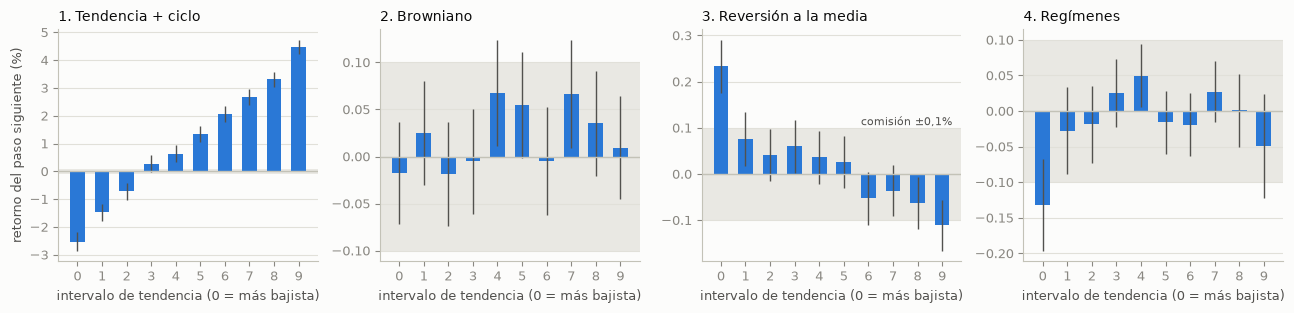

mercado,ciclo,browniano,reversion,regimenes
intervalo,,,,
0,-2.524,-0.017,0.233,-0.132
1,-1.475,0.025,0.077,-0.027
2,-0.715,-0.018,0.042,-0.019
3,0.277,-0.005,0.060,0.025
4,0.639,0.068,0.036,0.050
5,1.346,0.055,0.026,-0.016
6,2.070,-0.004,-0.053,-0.019
7,2.672,0.066,-0.036,0.027
8,3.313,0.035,-0.063,0.001


In [2]:
filas = []
for m in MERCADOS:
    g = GENERADORES[m]
    disc = Discretizador.ajustar(g, n_intervalos=10)
    for p in generar_series(g, 100, SEMILLA_VALIDACION):
        tr = tendencias(p)[:-1]      # tendencia observada en t
        ret = p[6:] / p[5:-1] - 1    # retorno de t a t+1
        filas.append(pd.DataFrame({"mercado": m, "intervalo": [disc.intervalo(x) for x in tr], "ret": ret}))
senal = (pd.concat(filas).groupby(["mercado", "intervalo"])["ret"]
         .agg(media="mean", error=lambda r: r.std() / np.sqrt(len(r))) * 100)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, m in zip(axes, MERCADOS):
    s = senal.loc[m]
    ax.axhspan(-0.1, 0.1, color=REJILLA, alpha=0.7, lw=0)
    ax.bar(s.index, s["media"], yerr=1.96 * s["error"], width=0.6, color=AZUL,
           error_kw=dict(ecolor=TINTA_2, elinewidth=1, capsize=0))
    ax.axhline(0, color=EJE, lw=1)
    ax.set_title(NOMBRES[m], loc="left")
    ax.set_xticks(range(10))
    ax.set_xlabel("intervalo de tendencia (0 = más bajista)")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("retorno del paso siguiente (%)")
axes[2].text(9.4, 0.1, "comisión ±0,1%", ha="right", va="bottom", color=TINTA_2, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS / "fase1_senal_por_intervalo.png", dpi=200)
plt.show()

senal.unstack("mercado")["media"][MERCADOS].round(3)

## 2. Entrenamiento

Hiperparámetros de esta primera pasada:

- **α decreciente**, $\alpha = 1/n(s,a)^{0.6}$, con $n(s,a)$ las visitas al par. Cumple las condiciones de convergencia de las slides 3 ($\sum \alpha = \infty$, $\sum \alpha^2 < \infty$). En un barrido rápido en validación, α constante (0,05 o 0,01) era demasiado ruidoso para señales del orden de la comisión.
- **γ = 0,9**: el estado no depende de las acciones salvo por la posición, así que γ sirve sobre todo para que el agente tenga en cuenta las comisiones futuras.
- **ε** baja exponencialmente de 1 a 0,01 durante el 70% de los episodios.
- **2000 episodios** de 500 pasos, con una serie nueva en cada episodio.
- **10 intervalos de tendencia**, simétricos y con el 0 como corte central.
- **Tres semillas** por algoritmo y mercado.

In [3]:
CONFIG = dict(n_episodios=2000, alpha=1.0, omega=0.6, gamma=0.9, eps_inicial=1.0, eps_final=0.01,
              frac_decaimiento=0.7, n_intervalos=10, evaluar_cada=100)
SEMILLAS = [0, 1, 2]
configs = [dict(mercado=m, algoritmo=a, seed=s, **CONFIG) for m in MERCADOS for a in ALGORITMOS for s in SEMILLAS]

t0 = time.perf_counter()
salidas = ejecutar_varios(configs, en_test=True)
print(f"{len(configs)} entrenamientos en {time.perf_counter() - t0:.0f} s (en paralelo)")


def de(m, algo):
    return [s for s in salidas if s["config"]["mercado"] == m and s["config"]["algoritmo"] == algo]

24 entrenamientos en 45 s (en paralelo)


## 3. Resultados en test

100 series nuevas por mercado. Para los agentes de RL se juntan las tres semillas (300 episodios de test); la última columna da la mediana de cada semilla por separado. El tiempo de entrenamiento incluye las evaluaciones periódicas en validación. Comentario sobre las métricas:

- En el mercado de ciclo unas pocas series con retornos enormes dominan la media, así que la métrica principal es la **mediana** del retorno.
- El Sharpe está anualizado suponiendo que cada paso es un día.

In [4]:
tablas = []
for m in MERCADOS:
    test = generar_series(GENERADORES[m], N_TEST, SEMILLA_TEST)
    evals = {nombre: evaluar(f(), test) for nombre, f in BASELINES.items()}
    tiempos, por_semilla = {}, {}
    for algo in ALGORITMOS:
        evals[algo] = pd.concat([s["test"] for s in de(m, algo)], ignore_index=True)
        tiempos[algo] = np.mean([s["resultado"].segundos for s in de(m, algo)])
        por_semilla[algo] = " / ".join(f'{s["test"]["retorno_pct"].median():,.1f}' for s in de(m, algo))
    t = resumir(evals)
    t["seg_entrenamiento"] = pd.Series(tiempos)
    t["mediana_por_semilla"] = pd.Series(por_semilla)
    t.insert(0, "mercado", m)
    tablas.append(t)
tabla = pd.concat(tablas).rename_axis("agente").reset_index()
tabla.to_csv(RESULTADOS / "fase1_test.csv", index=False)

columnas = ["mercado", "agente", "retorno_mediana_pct", "retorno_pct", "sharpe", "max_drawdown_pct",
            "operaciones", "tiempo_dentro_pct", "seg_entrenamiento", "mediana_por_semilla"]
with pd.option_context("display.float_format", lambda x: f"{x:,.1f}", "display.width", 200):
    print(tabla[columnas].to_string(index=False, na_rep=""))

  mercado       agente  retorno_mediana_pct  retorno_pct  sharpe  max_drawdown_pct  operaciones  tiempo_dentro_pct  seg_entrenamiento            mediana_por_semilla
    ciclo    aleatorio                453.1      1,951.2     1.3              78.3        164.7               49.7                                                  
    ciclo buy_and_hold              3,425.1     23,863.8     1.9              88.6          1.0              100.0                                                  
    ciclo     momentum             48,188.7    229,373.3     3.1              60.8         92.3               55.2                                                  
    ciclo   contrarian                -92.9        -80.1    -0.7              94.6         91.9               44.8                                                  
    ciclo    qlearning             42,874.9    226,602.0     2.9              69.6         53.6               70.4               15.4 46,086.9 / 38,660.4 / 45,593.0
    ciclo 

## 4. Curvas de aprendizaje

Mediana del retorno de la política greedy en las 20 series de validación, cada 100 episodios y promediada entre semillas. La línea gris es buy & hold en esas mismas series; la línea del 0 equivale a quedarse siempre fuera.

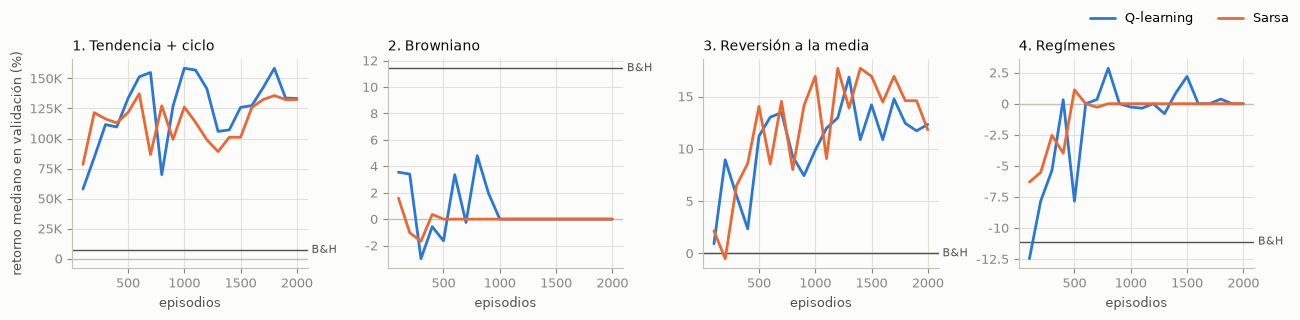

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, m in zip(axes, MERCADOS):
    val = generar_series(GENERADORES[m], N_VALIDACION, SEMILLA_VALIDACION)
    bh = evaluar(BASELINES["buy_and_hold"](), val)["retorno_pct"].median()
    ax.axhline(0, color=EJE, lw=1)
    ax.axhline(bh, color=TINTA_2, lw=1)
    ax.text(1.0, bh, " B&H", transform=ax.get_yaxis_transform(), va="center", color=TINTA_2, fontsize=8)
    for (algo, etiqueta), color in zip(ALGORITMOS.items(), (AZUL, NARANJA)):
        curvas = pd.concat([s["resultado"].validacion.set_index("episodio")["retorno_mediana_pct"]
                            for s in de(m, algo)], axis=1)
        ax.plot(curvas.index, curvas.mean(axis=1), color=color, label=etiqueta)
    ax.set_title(NOMBRES[m], loc="left")
    ax.set_xlabel("episodios")
    ax.yaxis.set_major_formatter(FuncFormatter(compacto))
axes[0].set_ylabel("retorno mediano en validación (%)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIGURAS / "fase1_curvas_aprendizaje.png", dpi=200)
plt.show()

## 5. Políticas aprendidas

Para cada estado (intervalo de tendencia × posición), la figura muestra en cuántas de las tres semillas la política greedy está **dentro** del mercado:

- Sin el activo, "dentro" significa que compra.
- Con el activo, "dentro" significa que no vende.

Dos columnas iguales indican que la política no depende de la posición; si difieren, el agente aplica una histéresis para no pagar comisiones de más.

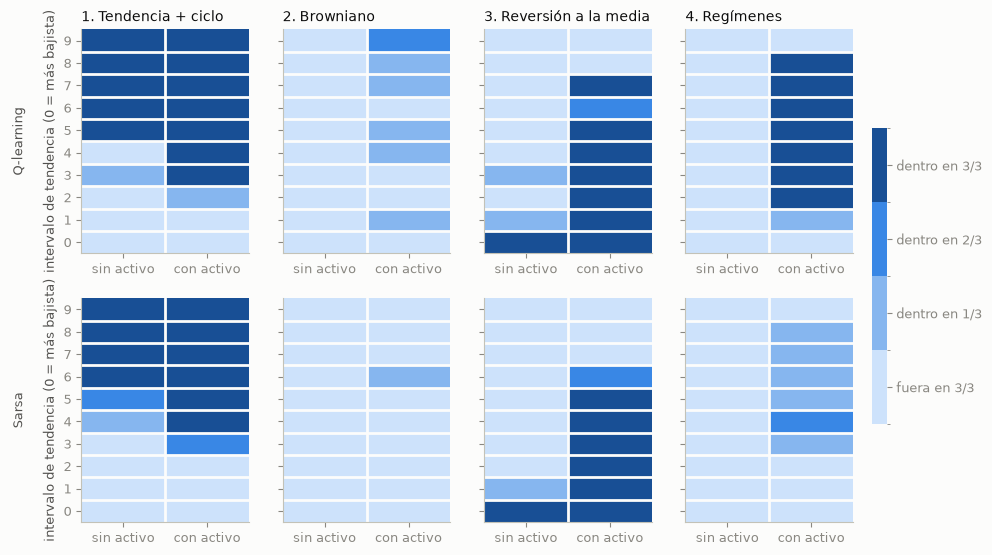

,1. Tendencia + ciclo,2. Browniano,3. Reversión a la media,4. Regímenes
corte 1,-0.1984,-0.0313,-0.0307,-0.0284
corte 2,-0.1318,-0.0204,-0.0201,-0.0166
corte 3,-0.0824,-0.0127,-0.0123,-0.0098
corte 4,-0.0402,-0.0061,-0.0059,-0.0046
corte 5,0.0000,0.0000,0.0000,0.0000
corte 6,0.0402,0.0061,0.0059,0.0046
corte 7,0.0824,0.0127,0.0123,0.0098
corte 8,0.1318,0.0204,0.0201,0.0166
corte 9,0.1984,0.0313,0.0307,0.0284


In [6]:
cmap = ListedColormap(["#cde2fb", "#86b6ef", "#3987e5", "#184f95"])
norm = BoundaryNorm([-1 / 6, 1 / 6, 1 / 2, 5 / 6, 7 / 6], cmap.N)
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4), sharey=True)
for i, (algo, etiqueta) in enumerate(ALGORITMOS.items()):
    for j, m in enumerate(MERCADOS):
        mapas = [mapa_politica(s["resultado"]) for s in de(m, algo)]
        dentro = sum((mp[["sin_activo", "con_activo"]] == "dentro").to_numpy(int) for mp in mapas) / len(mapas)
        ax = axes[i, j]
        im = ax.imshow(dentro, cmap=cmap, norm=norm, aspect="auto", origin="lower")
        ax.set_xticks([0, 1], ["sin activo", "con activo"])
        ax.set_yticks(range(10))
        ax.grid(False)
        if i == 0:
            ax.set_title(NOMBRES[m], loc="left")
        for k in range(1, 10):
            ax.axhline(k - 0.5, color=FONDO, lw=2)
        ax.axvline(0.5, color=FONDO, lw=2)
    axes[i, 0].set_ylabel(f"{etiqueta}\n\nintervalo de tendencia (0 = más bajista)")
cb = fig.colorbar(im, ax=axes, ticks=[0, 1 / 3, 2 / 3, 1], shrink=0.6, pad=0.02)
cb.ax.set_yticklabels(["fuera en 3/3", "dentro en 1/3", "dentro en 2/3", "dentro en 3/3"])
cb.outline.set_visible(False)
fig.savefig(FIGURAS / "fase1_politicas.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({NOMBRES[m]: Discretizador.ajustar(GENERADORES[m], n_intervalos=10).cortes for m in MERCADOS},
             index=[f"corte {k}" for k in range(1, 10)]).round(4)

## 6. Primeras conclusiones

Números de la tabla de test (mediana del retorno, salvo que se diga otra cosa).

- **Tendencia + ciclo.** La tendencia predice muy bien el paso siguiente: el retorno esperado va del −2,5% al +4,5% según el intervalo. Q-learning y Sarsa aprenden una política de **momentum con histéresis**: compran con tendencia positiva y, ya dentro, aguantan hasta que la tendencia se vuelve claramente negativa.
  - Operan menos que la regla de momentum (54–61 operaciones frente a 92).
  - Quedan a su nivel (+43.000% y +47.000% frente a +48.000%) y muy por encima de buy & hold (+3.400%).
  - Estos retornos son enormes porque el generador tiene un ruido del 10% por paso.
- **Browniano.** No hay señal, y los dos agentes aprenden a **no operar** (0%). Es lo esperado: todas las estrategias que operan pierden por comisiones (entre −12% y −15%).
  - Buy & hold queda en +0,7% de mediana, con un drawdown medio del 40%.
  - Con γ = 0,9 la deriva es demasiado pequeña para compensar el coste de comprar. Con γ más alto el agente podría preferir comprar y mantener: lo probaremos en la fase 2.
- **Reversión a la media.** Aprenden la estrategia esperada, **contrarian**, y más selectiva que la regla: compran solo en el intervalo más bajista y venden en los dos más alcistas.
  - Con un tercio de las operaciones de la regla contrarian (45 frente a 125) logran +17%, frente a +7% de la regla y −1% de buy & hold.
  - También tienen menos drawdown que la regla y que buy & hold.
- **Regímenes.** La hipótesis inicial (momentum) **no se cumple**, y la figura de señal explica por qué: la tendencia a 6 pasos apenas distingue los regímenes. Los extremos de tendencia salen sobre todo en el régimen bajista, que es más volátil.
  - Los agentes aprenden a no operar (0%), y eso supera a buy & hold (−20%) y a todas las reglas.
  - Para explotar los regímenes haría falta añadir información al estado, por ejemplo la volatilidad. Es un extra para la fase 4.
- **Q-learning frente a Sarsa.** En esta pasada dan resultados muy parecidos. En reversión, Sarsa pasa menos tiempo dentro del mercado (31% frente a 43%) y tiene algo menos de drawdown. Encaja con lo visto en Cliff Walking (Sarsa es más prudente), pero con tres semillas no es concluyente.
  - En browniano y regímenes, la columna "con activo" del mapa de políticas no importa: son estados a los que la política greedy nunca llega.
- **Convergencia y variabilidad.** Cada entrenamiento tarda unos 15 s. Con solo 20 series de validación las curvas son ruidosas, y además la mediana cambia bastante entre semillas (en reversión, del 11% al 21%). En la fase 3 usaremos más series de validación y más semillas, y un criterio de convergencia explícito.